In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from sklearn.feature_selection import SelectKBest, f_classif
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [60]:
data = pd.read_csv("breast_cancer_dataset.csv")

print("Dataset shape:", data.shape)
print("\nFirst 5 rows:")
display(data.head())

print("\nColumn names:")
print(data.columns.tolist())

print("\nMissing values:")
print(data.isnull().sum().sum())

Dataset shape: (569, 32)

First 5 rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Column names:
['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Missing values:
0


In [61]:
print(data.dtypes)

id                           int64
diagnosis                      str
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_worst           float64
compactness_worst          float64
concavity_worst     

In [62]:
X = data.drop(columns=["id", "diagnosis"])

# Convert diagnosis into binary labels
# M = 1 (Malignant), B = 0 (Benign)
y = data["diagnosis"].map({"B": 0, "M": 1})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nClass distribution:")
print(y.value_counts())
print("\nClass proportions:")
print(y.value_counts(normalize=True))

Feature matrix shape: (569, 30)
Target shape: (569,)

Class distribution:
diagnosis
0    357
1    212
Name: count, dtype: int64

Class proportions:
diagnosis
0    0.627417
1    0.372583
Name: proportion, dtype: float64


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Training set: (455, 30)
Test set: (114, 30)

Training class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Test class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [64]:

train_for_corr = X_train.copy()
train_for_corr["diagnosis"] = y_train


pearson_corr = (
    train_for_corr
    .corr(method="pearson")["diagnosis"]
    .drop("diagnosis")
    .sort_values(key=abs, ascending=False)
)

print("Features ranked by absolute Pearson correlation:")
display(pearson_corr.to_frame(name="Pearson_Correlation"))

Features ranked by absolute Pearson correlation:


,Pearson_Correlation
concave points_worst,0.786306
perimeter_worst,0.782881
radius_worst,0.777602
concave points_mean,0.775737
perimeter_mean,0.740027
area_worst,0.731761
radius_mean,0.728160
area_mean,0.703893
concavity_mean,0.683688
concavity_worst,0.643116


In [65]:
best_pearson_feature = pearson_corr.abs().idxmax()
best_pearson_correlation = pearson_corr[best_pearson_feature]

print("Best feature:", best_pearson_feature)
print("Pearson correlation:", best_pearson_correlation)

Best feature: concave points_worst
Pearson correlation: 0.7863060280462583


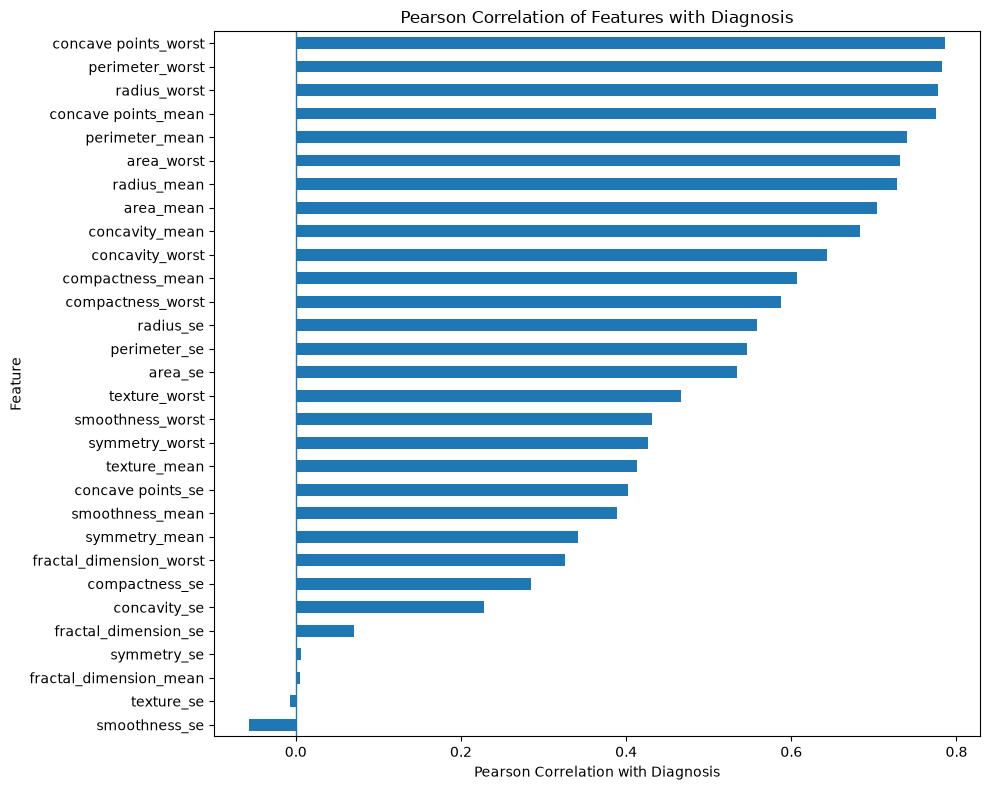

In [66]:
plt.figure(figsize=(10, 8))

pearson_corr.sort_values().plot(kind="barh")

plt.xlabel("Pearson Correlation with Diagnosis")
plt.ylabel("Feature")
plt.title("Pearson Correlation of Features with Diagnosis")
plt.axvline(0, linewidth=1)

plt.tight_layout()
plt.show()

# Q1(a): Logistic Regression — probabilities and log-odds.

In [67]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Train logistic regression
log_reg = LogisticRegression(
    max_iter=5000,
    random_state=42
)

log_reg.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")
print("Intercept:", log_reg.intercept_[0])

Logistic Regression model trained successfully.
Intercept: -0.24300532690560223


In [68]:

probabilities = log_reg.predict_proba(X_test_scaled)

prob_malignant = probabilities[:, 1]

y_pred = log_reg.predict(X_test_scaled)

probability_results = pd.DataFrame({
    "True_Label": y_test.values,
    "Predicted_Label": y_pred,
    "Probability_Benign": probabilities[:, 0],
    "Probability_Malignant": probabilities[:, 1]
})

display(probability_results.head(10))

,True_Label,Predicted_Label,Probability_Benign,Probability_Malignant
0,0,0,9.996354e-01,0.000365
1,1,1,1.074660e-08,1.000000
2,0,0,9.574321e-01,0.042568
3,1,1,4.238127e-01,0.576187
4,0,1,4.908445e-01,0.509155
5,0,0,9.993840e-01,0.000616
6,1,1,2.384659e-01,0.761534
7,0,0,9.989878e-01,0.001012
8,0,0,9.994313e-01,0.000569
9,0,0,9.892324e-01,0.010768


In [69]:
log_odds = log_reg.decision_function(X_test_scaled)

log_odds_results = pd.DataFrame({
    "True_Label": y_test.values,
    "Log_Odds": log_odds,
    "Probability_Malignant": prob_malignant
})

display(log_odds_results.head(10))

,True_Label,Log_Odds,Probability_Malignant
0,0,-7.916433,0.000365
1,1,18.348677,1.000000
2,0,-3.113153,0.042568
3,1,0.307141,0.576187
4,0,0.036626,0.509155
5,0,-7.391645,0.000616
6,1,1.161109,0.761534
7,0,-6.894644,0.001012
8,0,-7.471544,0.000569
9,0,-4.520390,0.010768


In [70]:
calculated_probability = 1 / (1 + np.exp(-log_odds))

comparison = pd.DataFrame({
    "Log_Odds": log_odds[:10],
    "Sklearn_Probability": prob_malignant[:10],
    "Calculated_Probability": calculated_probability[:10]
})

display(comparison)

,Log_Odds,Sklearn_Probability,Calculated_Probability
0,-7.916433,0.000365,0.000365
1,18.348677,1.000000,1.000000
2,-3.113153,0.042568,0.042568
3,0.307141,0.576187,0.576187
4,0.036626,0.509155,0.509155
5,-7.391645,0.000616,0.000616
6,1.161109,0.761534,0.761534
7,-6.894644,0.001012,0.001012
8,-7.471544,0.000569,0.000569
9,-4.520390,0.010768,0.010768


# Q1(b): coefficient ranking

In [71]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_reg.coef_[0]
})

coefficients["Absolute_Coefficient"] = coefficients["Coefficient"].abs()

coefficients = coefficients.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).reset_index(drop=True)

display(coefficients)

,Feature,Coefficient,Absolute_Coefficient
0,texture_worst,1.434093,1.434093
1,radius_se,1.233325,1.233325
2,symmetry_worst,1.061264,1.061264
3,concave points_mean,0.952813,0.952813
4,concavity_worst,0.911406,0.911406
5,area_se,0.909029,0.909029
6,compactness_se,-0.906925,0.906925
7,area_worst,0.900477,0.900477
8,radius_worst,0.896968,0.896968
9,concavity_mean,0.782298,0.782298


In [72]:
best_coefficient_feature = coefficients.loc[0, "Feature"]
best_coefficient_value = coefficients.loc[0, "Coefficient"]

print("Strongest feature:", best_coefficient_feature)
print("Coefficient:", best_coefficient_value)
print("Absolute coefficient:", abs(best_coefficient_value))

Strongest feature: texture_worst
Coefficient: 1.43409317103384
Absolute coefficient: 1.43409317103384


# Q1(c) — Single selected feature vs combination of features

In [73]:
selected_feature = best_pearson_feature

print("Pearson-selected feature:", selected_feature)

C_values = np.logspace(-4, 4, 15)

print("\nC values tested:")
print(C_values)

Pearson-selected feature: concave points_worst

C values tested:
[1.00000000e-04 3.72759372e-04 1.38949549e-03 5.17947468e-03
 1.93069773e-02 7.19685673e-02 2.68269580e-01 1.00000000e+00
 3.72759372e+00 1.38949549e+01 5.17947468e+01 1.93069773e+02
 7.19685673e+02 2.68269580e+03 1.00000000e+04]


In [74]:
X_train_single = X_train[[selected_feature]]
X_test_single = X_test[[selected_feature]]

print("Selected feature:", selected_feature)
print("Training shape:", X_train_single.shape)
print("Test shape:", X_test_single.shape)

Selected feature: concave points_worst
Training shape: (455, 1)
Test shape: (114, 1)


In [75]:
single_feature_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

single_param_grid = {
    "logistic__C": C_values
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

single_grid = GridSearchCV(
    estimator=single_feature_pipeline,
    param_grid=single_param_grid,
    cv=cv,
    scoring="neg_log_loss",
    n_jobs=-1,
    return_train_score=True
)

single_grid.fit(X_train_single, y_train)

print("Best C selected by 5-fold CV:")
print(single_grid.best_params_["logistic__C"])

print("\nBest mean CV log-loss:")
print(-single_grid.best_score_)

Best C selected by 5-fold CV:
3.727593720314938

Best mean CV log-loss:
0.2387493035276434


In [76]:
full_feature_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

full_param_grid = {
    "logistic__C": C_values
}

full_grid = GridSearchCV(
    estimator=full_feature_pipeline,
    param_grid=full_param_grid,
    cv=cv,
    scoring="neg_log_loss",
    n_jobs=-1,
    return_train_score=True
)

full_grid.fit(X_train, y_train)

print("Best C selected by 5-fold CV:")
print(full_grid.best_params_["logistic__C"])

print("\nBest mean CV log-loss:")
print(-full_grid.best_score_)

Best C selected by 5-fold CV:
1.0

Best mean CV log-loss:
0.07240696845282821


In [77]:
single_cv_results = pd.DataFrame({
    "C": C_values,
    "Single_Feature_CV_Log_Loss":
        -single_grid.cv_results_["mean_test_score"]
})

full_cv_results = pd.DataFrame({
    "C": C_values,
    "All_Features_CV_Log_Loss":
        -full_grid.cv_results_["mean_test_score"]
})

cv_comparison = single_cv_results.merge(
    full_cv_results,
    on="C"
)

display(cv_comparison)

,C,Single_Feature_CV_Log_Loss,All_Features_CV_Log_Loss
0,0.000100,0.655652,0.599072
1,0.000373,0.642108,0.497285
2,0.001389,0.598898,0.357540
3,0.005179,0.499715,0.237470
4,0.019307,0.375452,0.157149
5,0.071969,0.288674,0.109391
6,0.268270,0.249655,0.082844
7,1.000000,0.239498,0.072407
8,3.727594,0.238749,0.080245
9,13.894955,0.239076,0.105643


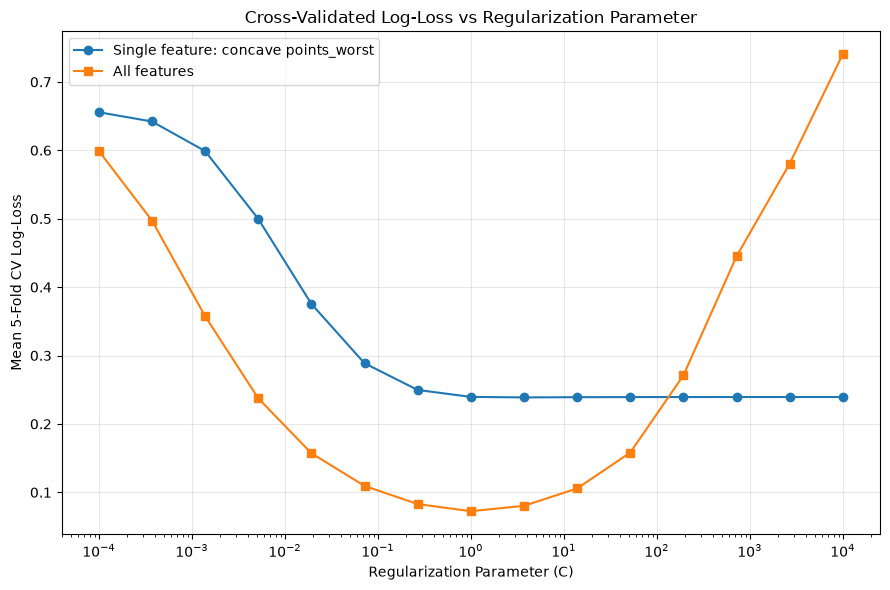

In [78]:
plt.figure(figsize=(9, 6))

plt.semilogx(
    C_values,
    cv_comparison["Single_Feature_CV_Log_Loss"],
    marker="o",
    label=f"Single feature: {selected_feature}"
)

plt.semilogx(
    C_values,
    cv_comparison["All_Features_CV_Log_Loss"],
    marker="s",
    label="All features"
)

plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Mean 5-Fold CV Log-Loss")
plt.title("Cross-Validated Log-Loss vs Regularization Parameter")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [79]:
single_test_logloss = []
full_test_logloss = []

for C in C_values:

    # -----------------------------
    # Single-feature model
    # -----------------------------
    single_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=C,
            max_iter=5000,
            random_state=42
        ))
    ])

    single_model.fit(X_train_single, y_train)

    single_prob = single_model.predict_proba(
        X_test_single
    )[:, 1]

    single_loss = log_loss(
        y_test,
        single_prob
    )

    single_test_logloss.append(single_loss)

    # -----------------------------
    # Full-feature model
    # -----------------------------
    full_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logistic", LogisticRegression(
            C=C,
            max_iter=5000,
            random_state=42
        ))
    ])

    full_model.fit(X_train, y_train)

    full_prob = full_model.predict_proba(
        X_test
    )[:, 1]

    full_loss = log_loss(
        y_test,
        full_prob
    )

    full_test_logloss.append(full_loss)


test_logloss_comparison = pd.DataFrame({
    "C": C_values,
    "Single_Feature_Test_Log_Loss": single_test_logloss,
    "All_Features_Test_Log_Loss": full_test_logloss
})

display(test_logloss_comparison)

,C,Single_Feature_Test_Log_Loss,All_Features_Test_Log_Loss
0,0.000100,0.651940,0.589483
1,0.000373,0.635870,0.482642
2,0.001389,0.585950,0.342667
3,0.005179,0.477791,0.226161
4,0.019307,0.347861,0.148802
5,0.071969,0.252668,0.102510
6,0.268270,0.201944,0.078946
7,1.000000,0.181125,0.077265
8,3.727594,0.174335,0.109318
9,13.894955,0.172391,0.171769


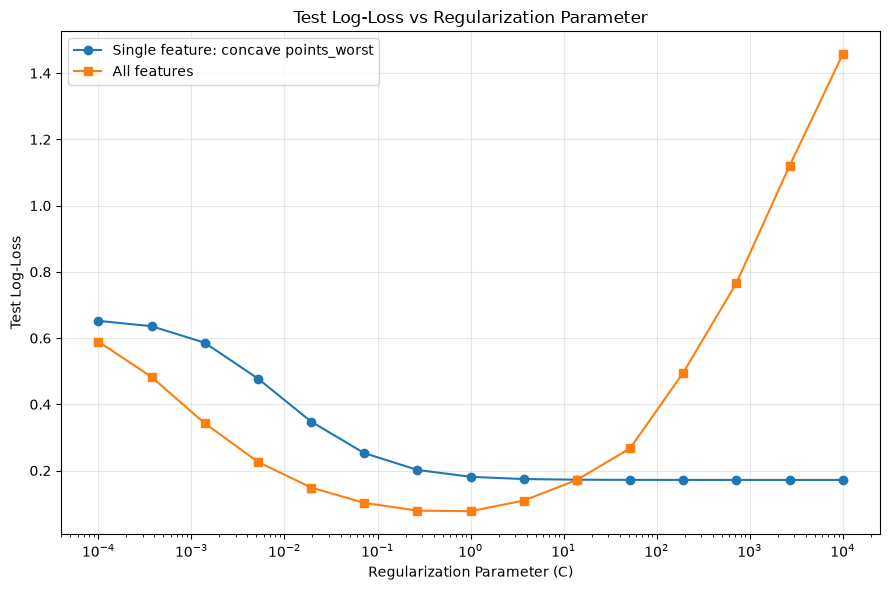

In [80]:

plt.figure(figsize=(9, 6))

plt.semilogx(
    C_values,
    single_test_logloss,
    marker="o",
    label=f"Single feature: {selected_feature}"
)

plt.semilogx(
    C_values,
    full_test_logloss,
    marker="s",
    label="All features"
)

plt.xlabel("Regularization Parameter (C)")
plt.ylabel("Test Log-Loss")
plt.title("Test Log-Loss vs Regularization Parameter")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Q1(d) — Logistic Regression vs KNN

In [81]:
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

# Different numbers of neighbors
knn_param_grid = {
    "knn__n_neighbors": list(range(1, 21)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:")
print(knn_grid.best_params_)

print("\nBest 5-fold CV ROC-AUC:")
print(knn_grid.best_score_)

Best KNN parameters:
{'knn__metric': 'euclidean', 'knn__n_neighbors': 12, 'knn__weights': 'distance'}

Best 5-fold CV ROC-AUC:
0.9898864809081527


In [82]:
best_logistic_C = full_grid.best_params_["logistic__C"]

final_logistic = Pipeline([
    ("scaler", StandardScaler()),
    ("logistic", LogisticRegression(
        C=best_logistic_C,
        max_iter=5000,
        random_state=42
    ))
])

final_logistic.fit(X_train, y_train)

final_knn = knn_grid.best_estimator_

print("Final Logistic Regression C:", best_logistic_C)
print("Final KNN parameters:", knn_grid.best_params_)

Final Logistic Regression C: 1.0
Final KNN parameters: {'knn__metric': 'euclidean', 'knn__n_neighbors': 12, 'knn__weights': 'distance'}


In [83]:
# Logistic Regression
lr_pred = final_logistic.predict(X_test)
lr_prob = final_logistic.predict_proba(X_test)[:, 1]

# KNN
knn_pred = final_knn.predict(X_test)
knn_prob = final_knn.predict_proba(X_test)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [84]:
def calculate_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1_Score": f1_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "Log_Loss": log_loss(y_true, y_prob)
    }


lr_metrics = calculate_metrics(
    y_test,
    lr_pred,
    lr_prob
)

knn_metrics = calculate_metrics(
    y_test,
    knn_pred,
    knn_prob
)

performance_comparison = pd.DataFrame(
    [lr_metrics, knn_metrics],
    index=["Logistic Regression", "KNN"]
)

display(performance_comparison)

,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Log_Loss
Logistic Regression,0.964912,0.975000,0.928571,0.95122,0.996032,0.077265
KNN,0.947368,0.973684,0.880952,0.92500,0.981812,0.418225


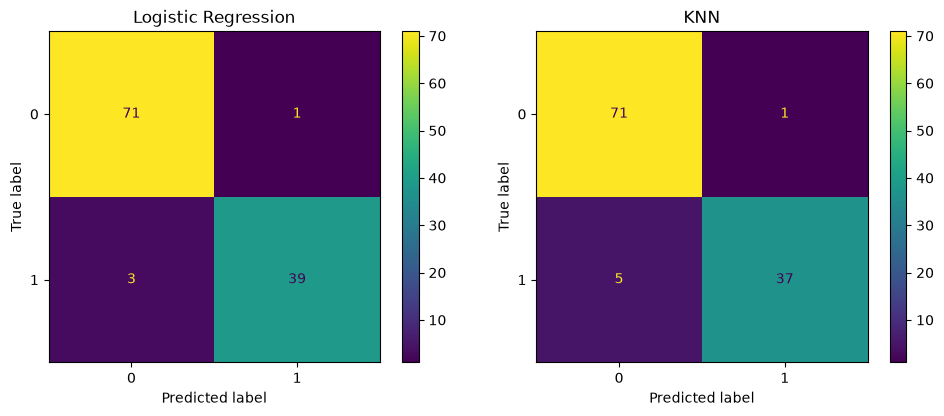

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    lr_pred,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    ax=axes[1]
)

axes[1].set_title("KNN")

plt.tight_layout()
plt.show()


In [86]:
print("LOGISTIC REGRESSION")

print(classification_report(
    y_test,
    lr_pred,
    target_names=["Benign", "Malignant"]
))

print("\nKNN")

print(classification_report(
    y_test,
    knn_pred,
    target_names=["Benign", "Malignant"]
))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114


KNN
              precision    recall  f1-score   support

      Benign       0.93      0.99      0.96        72
   Malignant       0.97      0.88      0.93        42

    accuracy                           0.95       114
   macro avg       0.95      0.93      0.94       114
weighted avg       0.95      0.95      0.95       114



# Q2 — Support Vector Machines

In [87]:

df = pd.read_csv("breast_cancer_dataset.csv")

print("Dataset shape:", df.shape)
display(df.head())

if "id" in df.columns:
    df = df.drop(columns=["id"])

y = df["diagnosis"]


if y.dtype == "object":
    y = y.map({"B": 0, "M": 1})

X = df.drop(columns=["diagnosis"])

print("Feature shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts())

Dataset shape: (569, 32)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Feature shape: (569, 30)

Target distribution:
diagnosis
B    357
M    212
Name: count, dtype: int64


In [88]:
selected_feature = best_pearson_feature

X_svm = X[[selected_feature]].copy()

print("Pearson-selected feature:", selected_feature)
print("Feature shape:", X_svm.shape)

Pearson-selected feature: concave points_worst
Feature shape: (569, 1)


In [89]:
selected_features = pearson_corr.abs().sort_values(ascending=False).head(10).index.tolist()

X_svm = X[selected_features].copy()

print("Features used for SVM:")
for i, feature in enumerate(selected_features, 1):
    print(i, feature)

print("Feature shape:", X_svm.shape)

Features used for SVM:
1 concave points_worst
2 perimeter_worst
3 radius_worst
4 concave points_mean
5 perimeter_mean
6 area_worst
7 radius_mean
8 area_mean
9 concavity_mean
10 concavity_worst
Feature shape: (569, 10)


# Q2(a) — SVM Classifiers with Different Kernels

In [90]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

X_svm_train, X_svm_test, y_svm_train, y_svm_test = train_test_split(
    X_svm,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)


svm_models = {
    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", probability=True, random_state=42))
    ]),
    
    "Polynomial_degree_2": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=2, probability=True, random_state=42))
    ]),
    
    "Polynomial_degree_3": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", degree=3, probability=True, random_state=42))
    ]),
    
    "RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", probability=True, random_state=42))
    ]),
    
    "Sigmoid": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="sigmoid", probability=True, random_state=42))
    ])
}


for name, model in svm_models.items():
    model.fit(X_svm_train, y_svm_train)

print("All SVM models trained successfully.")

All SVM models trained successfully.


# Q2(b) — Predicted Labels, Decision Scores and Probabilities

In [91]:
svm_results = {}

for name, model in svm_models.items():
    
    # Predicted class labels
    predicted_labels = model.predict(X_svm_test)
    
    # Decision scores
    decision_scores = model.decision_function(X_svm_test)
    
    # Predicted probability for positive class (M = 1)
    predicted_probabilities = model.predict_proba(X_svm_test)[:, 1]
    
    svm_results[name] = {
        "True_Label": y_svm_test.values,
        "Predicted_Label": predicted_labels,
        "Decision_Score": decision_scores,
        "Predicted_Probability": predicted_probabilities
    }

print("Predictions generated for all SVM kernels.")

Predictions generated for all SVM kernels.


In [92]:
svm_prediction_table = pd.DataFrame({
    "True_Label": y_svm_test.values
})

for name, results in svm_results.items():
    svm_prediction_table[f"{name}_Predicted_Label"] = results["Predicted_Label"]
    svm_prediction_table[f"{name}_Decision_Score"] = results["Decision_Score"]
    svm_prediction_table[f"{name}_Probability"] = results["Predicted_Probability"]

display(svm_prediction_table.head(10))

,True_Label,Linear_Predicted_Label,Linear_Decision_Score,Linear_Probability,Polynomial_degree_2_Predicted_Label,Polynomial_degree_2_Decision_Score,Polynomial_degree_2_Probability,Polynomial_degree_3_Predicted_Label,Polynomial_degree_3_Decision_Score,Polynomial_degree_3_Probability,RBF_Predicted_Label,RBF_Decision_Score,RBF_Probability,Sigmoid_Predicted_Label,Sigmoid_Decision_Score,Sigmoid_Probability
0,B,B,-2.342140,0.024875,B,-0.957806,0.280169,B,-1.861999,0.052134,B,-1.513800,0.013365,B,-6.583160,0.009880
1,M,M,6.534172,1.000000,M,2.760070,0.993775,M,28.003313,1.000000,M,1.215092,0.980559,M,2.222952,0.832494
2,B,B,-0.983238,0.187532,B,-1.498796,0.139544,B,-0.721858,0.331101,B,-0.472935,0.236252,M,3.643106,0.931341
3,M,M,0.003454,0.537268,B,-1.392224,0.161566,B,-0.731462,0.323506,B,-0.072824,0.508508,M,2.271594,0.837241
4,B,B,-1.875072,0.052919,B,-1.293563,0.184378,B,-1.164204,0.170614,B,-1.373676,0.020376,B,-6.358637,0.011575
5,B,B,-2.369925,0.023775,B,-0.602306,0.409361,B,-2.907523,0.006875,B,-1.147961,0.040046,B,-6.410888,0.011156
6,M,M,0.657272,0.772026,B,-0.716739,0.366686,B,-0.274251,0.538338,M,0.966088,0.959689,M,2.322548,0.842097
7,B,B,-1.904180,0.050512,B,-1.130832,0.227299,B,-0.908234,0.253071,B,-1.159819,0.038657,B,-3.692770,0.070740
8,B,B,-2.310004,0.026211,B,-1.102947,0.235322,B,-1.733236,0.063533,B,-1.543292,0.012229,B,-6.651271,0.009416
9,B,B,-2.493095,0.019450,B,-1.185438,0.212154,B,-1.271635,0.142986,B,-1.695454,0.007730,B,-6.811733,0.008408


# Q2(c) — Hyperparameter Tuning Using 5-Fold Cross-Validation

In [93]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# SVM pipelines


svm_pipelines = {

    "Linear": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="linear", probability=True, random_state=42))
    ]),

    "Polynomial": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly", probability=True, random_state=42))
    ]),

    "RBF": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", probability=True, random_state=42))
    ]),

    "Sigmoid": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="sigmoid", probability=True, random_state=42))
    ])
}


# Hyperparameter grids


svm_param_grids = {

    "Linear": {
        "svm__C": [0.01, 0.1, 1, 10, 100]
    },

    "Polynomial": {
        "svm__C": [0.01, 0.1, 1, 10, 100],
        "svm__degree": [2, 3],
        "svm__gamma": ["scale", "auto"]
    },

    "RBF": {
        "svm__C": [0.01, 0.1, 1, 10, 100],
        "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]
    },

    "Sigmoid": {
        "svm__C": [0.01, 0.1, 1, 10, 100],
        "svm__gamma": ["scale", "auto", 0.001, 0.01, 0.1, 1]
    }
}


# Perform GridSearchCV


best_svm_models = {}
svm_cv_results = {}

for name in svm_pipelines:

    print("=" * 60)
    print(name, "SVM")
    print("=" * 60)

    grid = GridSearchCV(
        estimator=svm_pipelines[name],
        param_grid=svm_param_grids[name],
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X_svm_train, y_svm_train)

    best_svm_models[name] = grid.best_estimator_
    svm_cv_results[name] = grid

    print("Best parameters:")
    print(grid.best_params_)

    print("\nBest 5-fold CV ROC-AUC:")
    print(grid.best_score_)
    print()

Linear SVM
Best parameters:
{'svm__C': 1}

Best 5-fold CV ROC-AUC:
0.9855521155830754

Polynomial SVM
Best parameters:
{'svm__C': 1, 'svm__degree': 3, 'svm__gamma': 'scale'}

Best 5-fold CV ROC-AUC:
0.9817337461300311

RBF SVM
Best parameters:
{'svm__C': 10, 'svm__gamma': 0.01}

Best 5-fold CV ROC-AUC:
0.9847265221878224

Sigmoid SVM
Best parameters:
{'svm__C': 100, 'svm__gamma': 0.01}

Best 5-fold CV ROC-AUC:
0.9855521155830754



# Q2(d) — Comparison of SVM Kernels with KNN on the Hold-Out Test Set

In [98]:
svm_test_results = {}

# Convert true labels to 0/1
if y_test.dtype == "object":
    y_svm_test = y_test.map({"B": 0, "M": 1}).to_numpy()
else:
    y_svm_test = np.asarray(y_test).astype(int).ravel()

X_svm_test = X_test[selected_features].copy()

print("SVM test feature shape:", X_svm_test.shape)
print("SVM test label shape:", y_svm_test.shape)

for name, model in best_svm_models.items():

    # Predicted labels are B/M
    y_pred_raw = model.predict(X_svm_test)

    # Convert B/M predictions to 0/1
    y_pred = pd.Series(y_pred_raw).map({"B": 0, "M": 1}).to_numpy()

    # Decision scores
    y_score = model.decision_function(X_svm_test)

    # Probability of positive class (M)
    y_prob = model.predict_proba(X_svm_test)[:, 1]

    print(name, ":", len(y_svm_test), len(y_pred))

    svm_test_results[name] = {
        "Accuracy": accuracy_score(y_svm_test, y_pred),
        "Precision": precision_score(y_svm_test, y_pred),
        "Recall": recall_score(y_svm_test, y_pred),
        "F1_Score": f1_score(y_svm_test, y_pred),
        "ROC_AUC": roc_auc_score(y_svm_test, y_score),
        "Log_Loss": log_loss(y_svm_test, y_prob)
    }

print("\nSVM test-set evaluation completed.")

SVM test feature shape: (114, 10)
SVM test label shape: (114,)
Linear : 114 114
Polynomial : 114 114
RBF : 114 114
Sigmoid : 114 114

SVM test-set evaluation completed.


In [100]:
knn_pred = np.asarray(final_knn.predict(X_test)).astype(int).ravel()

# KNN probability of positive class
knn_prob = final_knn.predict_proba(X_test)[:, 1]

# Add KNN results
svm_test_results["KNN"] = {
    "Accuracy": accuracy_score(y_svm_test, knn_pred),
    "Precision": precision_score(y_svm_test, knn_pred),
    "Recall": recall_score(y_svm_test, knn_pred),
    "F1_Score": f1_score(y_svm_test, knn_pred),
    "ROC_AUC": roc_auc_score(y_svm_test, knn_prob),
    "Log_Loss": log_loss(y_svm_test, knn_prob)
}

# Create comparison table
performance_comparison_q2 = pd.DataFrame(svm_test_results).T

display(performance_comparison_q2)

,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Log_Loss
Linear,0.973684,1.000000,0.928571,0.962963,0.998677,0.101824
Polynomial,0.877193,1.000000,0.666667,0.800000,0.994048,0.195834
RBF,0.964912,1.000000,0.904762,0.950000,0.997354,0.094264
Sigmoid,0.973684,1.000000,0.928571,0.962963,0.998347,0.138901
KNN,0.947368,0.973684,0.880952,0.925000,0.981812,0.418225


In [101]:
svm_prediction_table = pd.DataFrame({
    "True_Label": y_svm_test
})

for name, model in best_svm_models.items():

    predicted_labels = model.predict(X_svm_test)

    # Convert B/M to 0/1
    predicted_labels = pd.Series(predicted_labels).map({
        "B": 0,
        "M": 1
    }).to_numpy()

    decision_scores = model.decision_function(X_svm_test)
    predicted_probabilities = model.predict_proba(X_svm_test)[:, 1]

    svm_prediction_table[f"{name}_Predicted_Label"] = predicted_labels
    svm_prediction_table[f"{name}_Decision_Score"] = decision_scores
    svm_prediction_table[f"{name}_Probability"] = predicted_probabilities

display(svm_prediction_table.head(10))

,True_Label,Linear_Predicted_Label,Linear_Decision_Score,Linear_Probability,Polynomial_Predicted_Label,Polynomial_Decision_Score,Polynomial_Probability,RBF_Predicted_Label,RBF_Decision_Score,RBF_Probability,Sigmoid_Predicted_Label,Sigmoid_Decision_Score,Sigmoid_Probability
0,0,0,-2.342140,0.024875,0,-1.861999,0.052134,0,-2.122768,0.016759,0,-2.373522,0.051719
1,1,1,6.534172,1.000000,1,28.003313,1.000000,1,5.070234,1.000000,1,6.444367,0.999999
2,0,0,-0.983238,0.187532,0,-0.721858,0.331101,0,-0.363517,0.368230,0,-0.959214,0.221888
3,1,1,0.003454,0.537268,0,-0.731462,0.323506,1,0.117036,0.604661,1,0.005602,0.475431
4,0,0,-1.875072,0.052919,0,-1.164204,0.170614,0,-1.768138,0.034077,0,-1.884929,0.085946
5,0,0,-2.369925,0.023775,0,-2.907523,0.006875,0,-2.017389,0.020704,0,-2.593799,0.039910
6,1,1,0.657272,0.772026,0,-0.274251,0.538338,1,0.915365,0.883804,1,0.709557,0.678159
7,0,0,-1.904180,0.050512,0,-0.908234,0.253071,0,-1.466455,0.061812,0,-1.900088,0.084530
8,0,0,-2.310004,0.026211,0,-1.733236,0.063533,0,-2.104404,0.017389,0,-2.357730,0.052684
9,0,0,-2.493095,0.019450,0,-1.271635,0.142986,0,-2.099061,0.017576,0,-2.557531,0.041656


# Q3(a) — K-Means Clustering for k = 2, 3, 4, 5, 6

In [103]:
from sklearn.cluster import KMeans


In [104]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Scale complete dataset
kmeans_scaler = StandardScaler()
X_kmeans = kmeans_scaler.fit_transform(X)

print("K-means feature shape:", X_kmeans.shape)

# Values of k
k_values = [2, 3, 4, 5, 6]

kmeans_results = {}

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_kmeans)

    kmeans_results[k] = {
        "model": kmeans,
        "inertia": kmeans.inertia_,
        "labels": cluster_labels,
        "centroids": kmeans.cluster_centers_
    }

    print(f"\nk = {k}")
    print(f"Inertia: {kmeans.inertia_}")
    print(f"Cluster labels shape: {cluster_labels.shape}")
    print(f"Centroids shape: {kmeans.cluster_centers_.shape}")

K-means feature shape: (569, 30)

k = 2
Inertia: 11595.526607115782
Cluster labels shape: (569,)
Centroids shape: (2, 30)

k = 3
Inertia: 10061.797818243696
Cluster labels shape: (569,)
Centroids shape: (3, 30)

k = 4
Inertia: 9258.989105136361
Cluster labels shape: (569,)
Centroids shape: (4, 30)

k = 5
Inertia: 8558.660667250888
Cluster labels shape: (569,)
Centroids shape: (5, 30)

k = 6
Inertia: 7970.263835292895
Cluster labels shape: (569,)
Centroids shape: (6, 30)


# Q3(b) — Elbow + Silhouette Analysis


In [105]:
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertias = []
silhouette_scores = []

for k in k_values:

    
    inertias.append(kmeans_results[k]["inertia"])

    
    score = silhouette_score(
        X_kmeans,
        kmeans_results[k]["labels"]
    )

    silhouette_scores.append(score)

    print(f"k = {k} | Inertia = {kmeans_results[k]['inertia']:.2f} | "
          f"Silhouette Score = {score:.4f}")

k = 2 | Inertia = 11595.53 | Silhouette Score = 0.3434
k = 3 | Inertia = 10061.80 | Silhouette Score = 0.3144
k = 4 | Inertia = 9258.99 | Silhouette Score = 0.2833
k = 5 | Inertia = 8558.66 | Silhouette Score = 0.1582
k = 6 | Inertia = 7970.26 | Silhouette Score = 0.1604


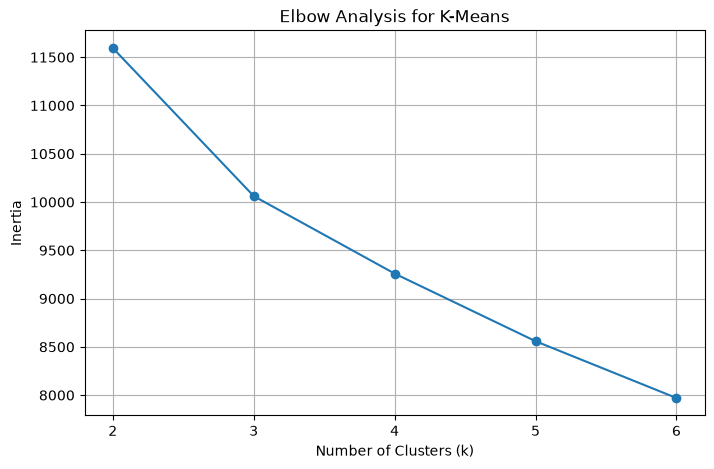

In [106]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Analysis for K-Means")
plt.xticks(k_values)
plt.grid(True)

plt.show()


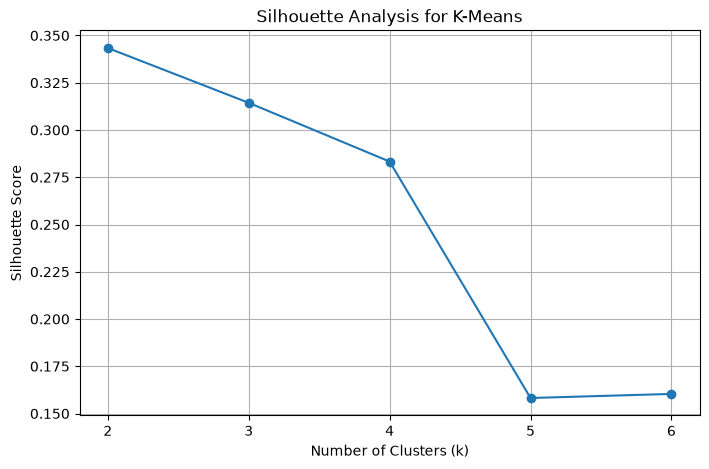

In [107]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis for K-Means")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [108]:
best_k = k_values[silhouette_scores.index(max(silhouette_scores))]

print("Preferred k based on silhouette score:", best_k)


Preferred k based on silhouette score: 2


# Q3(c) — PCA Visualizations of Clustering

In [109]:
from sklearn.decomposition import PCA

# Select the K-Means model for the preferred k
final_kmeans = kmeans_results[best_k]["model"]
final_cluster_labels = kmeans_results[best_k]["labels"]

# Apply PCA to the scaled features
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_kmeans)

print("PCA shape:", X_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained:",
      pca.explained_variance_ratio_.sum())

PCA shape: (569, 2)
Explained variance ratio: [0.44272026 0.18971182]
Total variance explained: 0.6324320765155944


True label values: [0 1]
PCA shape: (569, 2)
Number of samples: 569


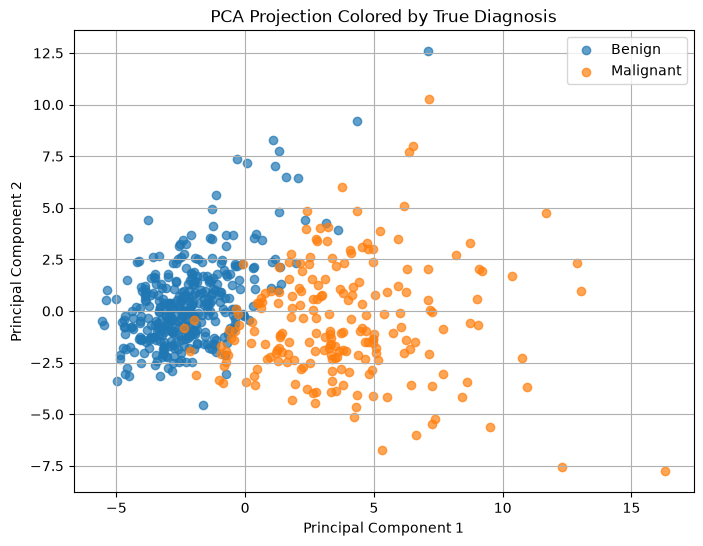

In [112]:
y_numeric = y.astype(str).map({
    "B": 0,
    "M": 1
}).to_numpy()

print("True label values:", np.unique(y_numeric))
print("PCA shape:", X_pca.shape)
print("Number of samples:", len(y_numeric))

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[y_numeric == 0, 0],
    X_pca[y_numeric == 0, 1],
    label="Benign",
    alpha=0.7
)

plt.scatter(
    X_pca[y_numeric == 1, 0],
    X_pca[y_numeric == 1, 1],
    label="Malignant",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection Colored by True Diagnosis")
plt.legend()
plt.grid(True)

plt.show()

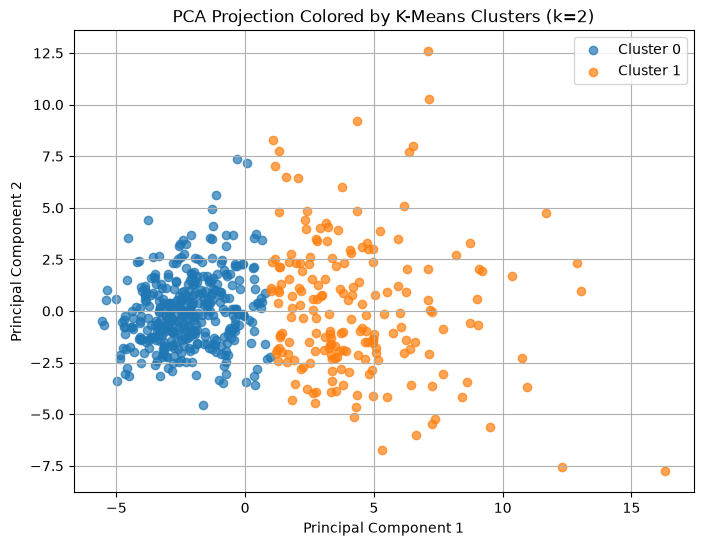

In [113]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[final_cluster_labels == 0, 0],
    X_pca[final_cluster_labels == 0, 1],
    label="Cluster 0",
    alpha=0.7
)

plt.scatter(
    X_pca[final_cluster_labels == 1, 0],
    X_pca[final_cluster_labels == 1, 1],
    label="Cluster 1",
    alpha=0.7
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection Colored by K-Means Clusters (k=2)")
plt.legend()
plt.grid(True)

plt.show()

In [114]:
final_cluster_labels = kmeans_results[best_k]["labels"]


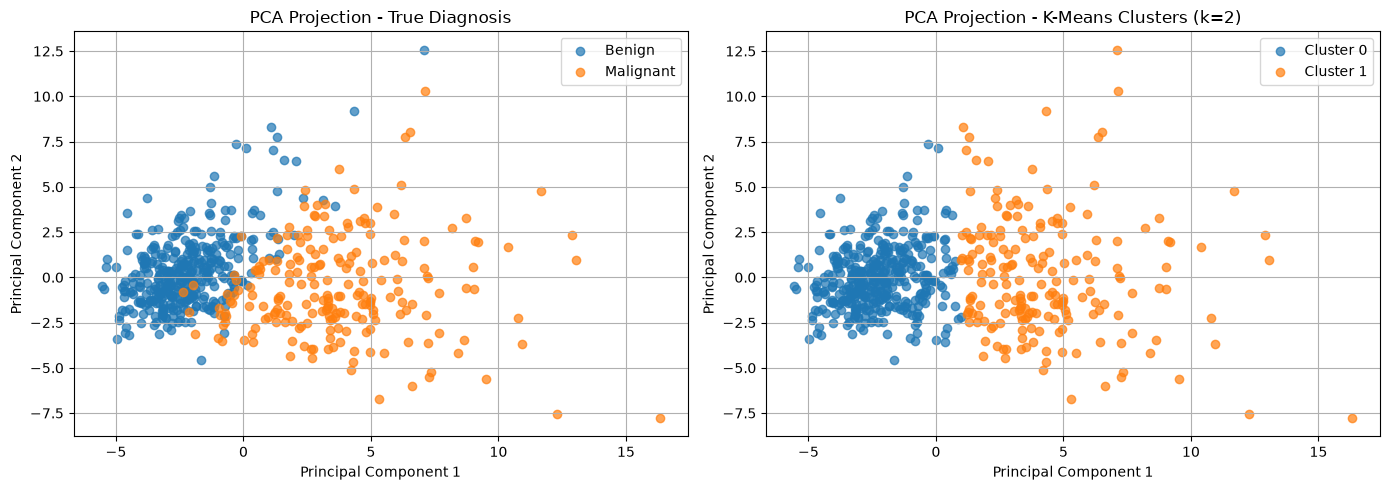

In [115]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Plot 1: True labels ----
axes[0].scatter(
    X_pca[y_numeric == 0, 0],
    X_pca[y_numeric == 0, 1],
    label="Benign",
    alpha=0.7
)

axes[0].scatter(
    X_pca[y_numeric == 1, 0],
    X_pca[y_numeric == 1, 1],
    label="Malignant",
    alpha=0.7
)

axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].set_title("PCA Projection - True Diagnosis")
axes[0].legend()
axes[0].grid(True)


# ---- Plot 2: K-Means clusters ----
axes[1].scatter(
    X_pca[final_cluster_labels == 0, 0],
    X_pca[final_cluster_labels == 0, 1],
    label="Cluster 0",
    alpha=0.7
)

axes[1].scatter(
    X_pca[final_cluster_labels == 1, 0],
    X_pca[final_cluster_labels == 1, 1],
    label="Cluster 1",
    alpha=0.7
)

axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].set_title("PCA Projection - K-Means Clusters (k=2)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

The preferred number of clusters is k = 2, which agrees with the two known classes in the dataset. The silhouette score is highest at k = 2 (0.3434) and decreases for higher values of k. The PCA visualizations show that the two K-Means clusters broadly correspond to the benign and malignant groups, although some overlap is present. Since K-Means is unsupervised, the true diagnosis labels were not used during clustering; they are shown only for comparison